# Credit Card Fraud Detection: Analysis

This notebook explores the data, explains the features and compares four models.
The final model is trained by `train.py`. This notebook is for analysis and the report.

| Section | What it covers |
| --- | --- |
| 1 | Load data |
| 2 | Exploratory data analysis (EDA) |
| 3 | Feature engineering |
| 4 | Why accuracy is not enough |
| 5 | Model comparison |
| 6 | Curves and confusion matrices |
| 7 | Threshold tuning |
| 8 | Feature importance and decision tree |
| 9 | Conclusion |

**Dataset:** [kartik2112/fraud-detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection) (simulated card transactions).
Amounts are converted from USD to INR so the model works in rupees.

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # import helpers from train.py

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    precision_recall_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from train import (
    DATA_DIR,
    FEATURES,
    NUM_FEATURES,
    RANDOM_STATE,
    TRAIN_CSV,
    best_threshold,
    build_pipeline,
    candidate_models,
    compute_metrics,
    ensure_dataset,
    feature_importance,
    feature_names,
    load_dataset,
)

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Load data

In [2]:
ensure_dataset()
raw = pd.read_csv(DATA_DIR / TRAIN_CSV, nrows=5)
raw.T

,0,1,2,3,4
Unnamed: 0,0,1,2,3,4
trans_date_trans_time,2019-01-01 00:00:18,2019-01-01 00:00:44,2019-01-01 00:00:51,2019-01-01 00:01:16,2019-01-01 00:03:06
cc_num,2703186189652095,630423337322,38859492057661,3534093764340240,375534208663984
merchant,"fraud_Rippin, Kub and Mann","fraud_Heller, Gutmann and Zieme",fraud_Lind-Buckridge,"fraud_Kutch, Hermiston and Farrell",fraud_Keeling-Crist
category,misc_net,grocery_pos,entertainment,gas_transport,misc_pos
amt,4.9700,107.2300,220.1100,45.0000,41.9600
first,Jennifer,Stephanie,Edward,Jeremy,Tyler
last,Banks,Gill,Sanchez,White,Garcia
gender,F,F,M,M,M
street,561 Perry Cove,43039 Riley Greens Suite 393,594 White Dale Suite 530,9443 Cynthia Court Apt. 038,408 Bradley Rest


In [3]:
train_df, test_df = load_dataset()  # features for the train and test files
print(f"Train rows: {len(train_df):,}")
print(f"Test rows:  {len(test_df):,}")
train_df.head()

Train rows: 1,296,675
Test rows:  555,719


,amount_inr,hour,is_night,day_of_week,age,txn_count_24h,hours_since_last,amt_to_avg_ratio,category,is_fraud
0,412.5100,0,1,1,30.8145,0.0000,720.0000,1.0000,misc_net,0
1,8900.0900,0,1,1,40.5311,0.0000,720.0000,1.0000,grocery_pos,0
2,18269.1300,0,1,1,56.9500,0.0000,720.0000,1.0000,entertainment,0
3,3735.0000,0,1,1,51.9699,0.0000,720.0000,1.0000,gas_transport,0
4,3482.6800,0,1,1,32.7639,0.0000,720.0000,1.0000,misc_pos,0


## 2. Exploratory data analysis

### Class balance

is_fraud
Normal    1289169
Fraud        7506
Fraud rate: 0.58%


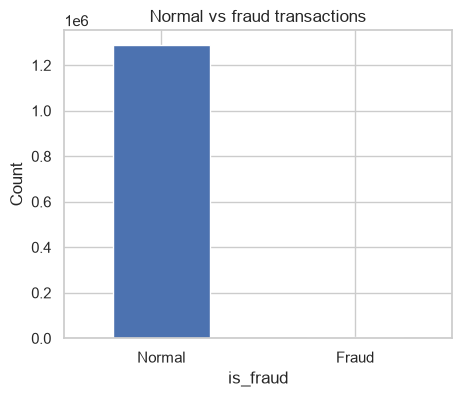

In [4]:
counts = train_df["is_fraud"].value_counts().rename({0: "Normal", 1: "Fraud"})
print(counts.to_string())
print(f"Fraud rate: {train_df['is_fraud'].mean():.2%}")

fig, ax = plt.subplots(figsize=(5, 4))
counts.plot.bar(ax=ax, color=["#4C72B0", "#C44E52"], rot=0)
ax.set(title="Normal vs fraud transactions", ylabel="Count")
plt.show()

Fraud is less than 1% of the data. This is a **highly imbalanced** problem,
so we use class weights during training and focus on recall, precision and PR-AUC.

### Amount

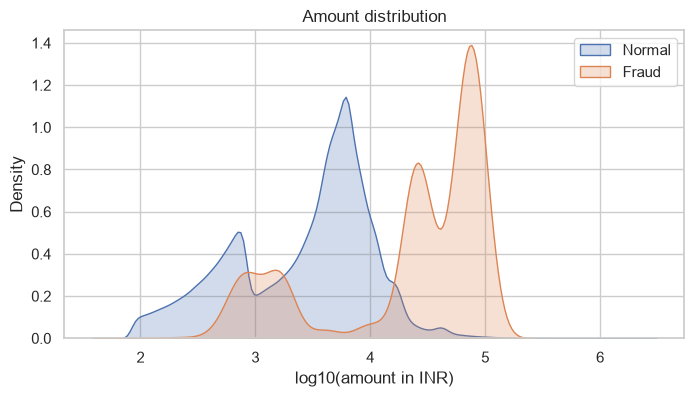

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0000,5616.3701,12782.6616,83.0000,797.6300,3924.2400,6850.8200,2402758.7000
1,7506.0000,44099.5676,32416.4858,87.9800,20389.9875,32909.9150,74772.6250,114211.3200


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, part in train_df.groupby("is_fraud"):
    sns.kdeplot(np.log10(part["amount_inr"]), ax=ax, fill=True, label="Fraud" if label else "Normal")
ax.set(xlabel="log10(amount in INR)", title="Amount distribution")
ax.legend()
plt.show()

train_df.groupby("is_fraud")["amount_inr"].describe()

Fraud transactions are usually much larger than normal ones.

### Hour of day

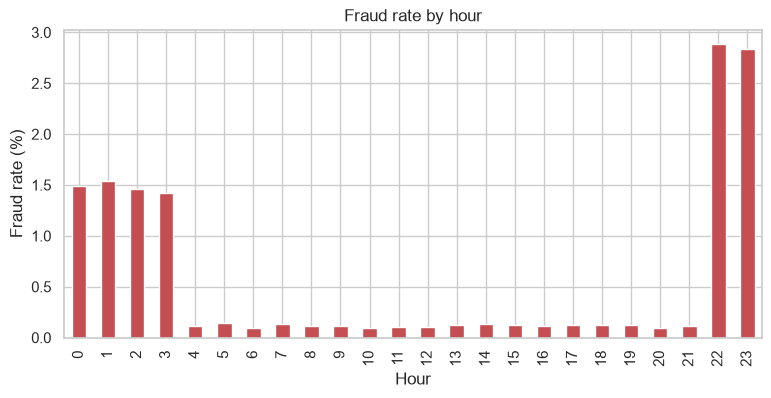

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
train_df.groupby("hour")["is_fraud"].mean().mul(100).plot.bar(ax=ax, color="#C44E52")
ax.set(xlabel="Hour", ylabel="Fraud rate (%)", title="Fraud rate by hour")
plt.show()

Most fraud happens late at night (22:00 to 03:00).

### Merchant category

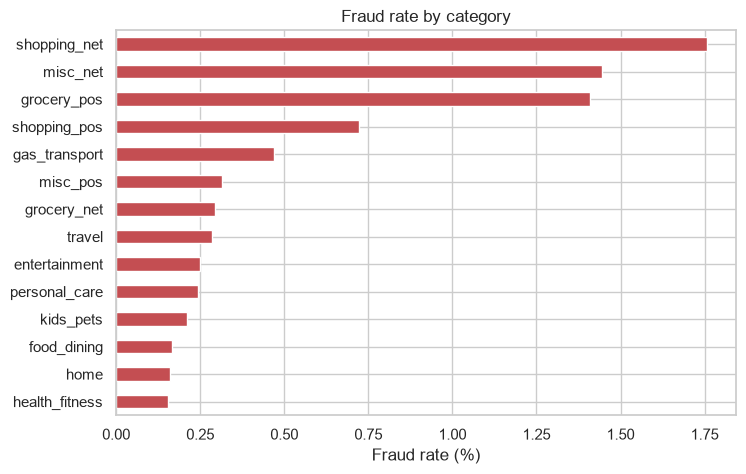

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
train_df.groupby("category")["is_fraud"].mean().mul(100).sort_values().plot.barh(ax=ax, color="#C44E52")
ax.set(xlabel="Fraud rate (%)", ylabel="", title="Fraud rate by category")
plt.show()

### Cardholder age

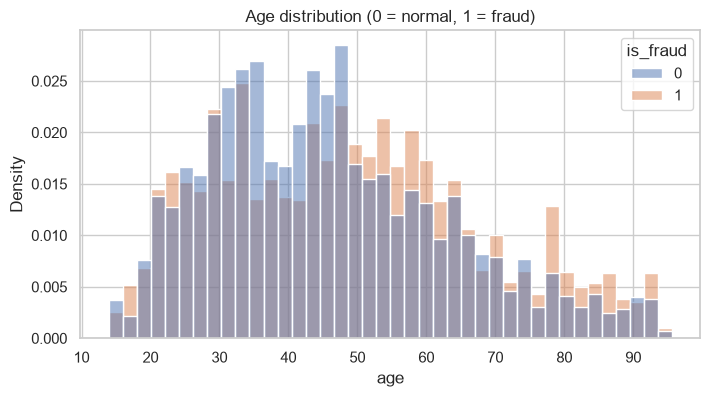

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=train_df, x="age", hue="is_fraud", stat="density", common_norm=False, bins=40, ax=ax)
ax.set(title="Age distribution (0 = normal, 1 = fraud)")
plt.show()

## 3. Feature engineering

| Feature | How it is made | Why it helps |
| --- | --- | --- |
| `amount_inr` | Amount × 83 | Fraud amounts are larger |
| `hour`, `is_night` | From transaction time | Fraud happens at night |
| `day_of_week` | From transaction time | Weekly pattern |
| `age` | Transaction date minus date of birth | Some age groups are targeted more |
| `txn_count_24h` | Card's transactions in the previous 24 hours | Fraudsters use a card many times quickly |
| `hours_since_last` | Gap from the card's previous transaction | Very short gaps are suspicious |
| `amt_to_avg_ratio` | Amount ÷ card's average past amount | Spending far above normal is suspicious |
| `category` | One-hot encoded | Some categories are riskier |

History features only use **past** transactions of the same card, so there is no data leakage.

Location columns (latitude, longitude, city population) were checked and dropped:
they look the same for fraud and normal rows in this dataset.

In [9]:
train_df.groupby("is_fraud")[NUM_FEATURES].median().T.rename(columns={0: "Normal", 1: "Fraud"})

is_fraud,Normal,Fraud
amount_inr,3924.2400,32909.9150
hour,14.0000,22.0000
is_night,0.0000,1.0000
day_of_week,3.0000,3.0000
age,43.9562,47.8029
txn_count_24h,3.0000,4.0000
hours_since_last,4.6236,1.4039
amt_to_avg_ratio,0.6649,5.1637


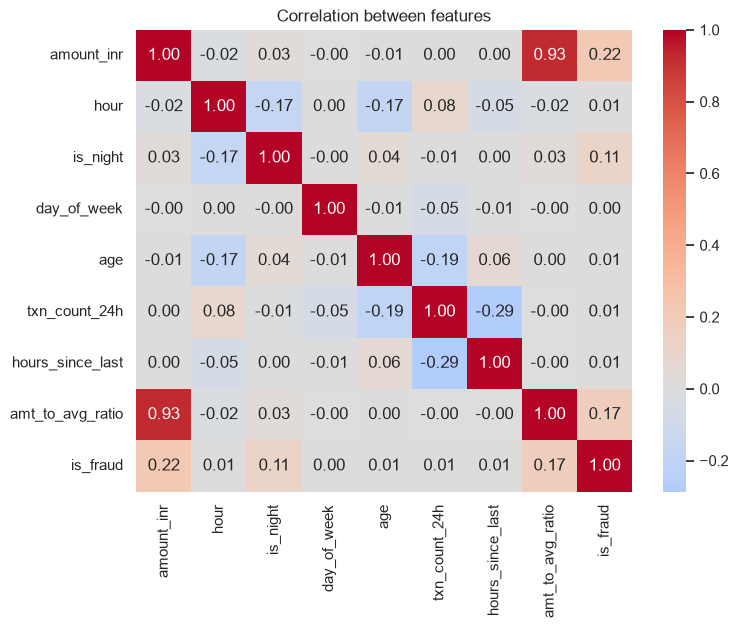

In [10]:
corr = train_df[NUM_FEATURES + ["is_fraud"]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set(title="Correlation between features")
plt.show()

## 4. Why accuracy is not enough

In [11]:
X_test, y_test = test_df[FEATURES], test_df["is_fraud"]

dummy = DummyClassifier(strategy="most_frequent").fit(X_test, y_test)
m = compute_metrics(y_test, dummy.predict_proba(X_test)[:, 1], 0.5)
print(f"A model that always says 'normal' gets accuracy {m['accuracy']:.2%}")
print(f"...but its recall is {m['recall']:.0%}: it catches zero fraud.")

A model that always says 'normal' gets accuracy 99.61%
...but its recall is 0%: it catches zero fraud.


So we judge models mainly by **recall** (how much fraud we catch), **precision** (how many alerts are real)
and **PR-AUC** (the best single score for imbalanced data).

## 5. Model comparison

To keep the notebook fast, models are trained on a 30% stratified sample of the training data. `train.py` uses all of it.

In [12]:
sample = train_df.groupby("is_fraud").sample(frac=0.3, random_state=RANDOM_STATE)
X_fit, X_val, y_fit, y_val = train_test_split(
    sample[FEATURES], sample["is_fraud"], test_size=0.2, stratify=sample["is_fraud"], random_state=RANDOM_STATE,
)
pos_weight = (y_fit == 0).sum() / (y_fit == 1).sum()

pipelines, results = {}, {}
for name, model in candidate_models(pos_weight).items():
    pipelines[name] = build_pipeline(model).fit(X_fit, y_fit)
    proba = pipelines[name].predict_proba(X_test)[:, 1]
    m = compute_metrics(y_test, proba, 0.5)
    m.pop("confusion_matrix")
    results[name] = m
    print(f"{name:20s} PR-AUC {m['pr_auc']:.4f}")

scores = pd.DataFrame(results).T
scores.style.highlight_max(color="#c6efce").format("{:.4f}")

Logistic Regression  PR-AUC 0.1766


Decision Tree        PR-AUC 0.6409


Random Forest        PR-AUC 0.8149


XGBoost              PR-AUC 0.8859


,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc
Logistic Regression,0.8648,0.0256,0.9179,0.0498,0.8646,0.9501,0.1766
Decision Tree,0.9686,0.1041,0.9385,0.1875,0.9687,0.9665,0.6409
Random Forest,0.9921,0.3170,0.9124,0.4705,0.9924,0.9944,0.8149
XGBoost,0.9977,0.6561,0.8760,0.7502,0.9982,0.9972,0.8859


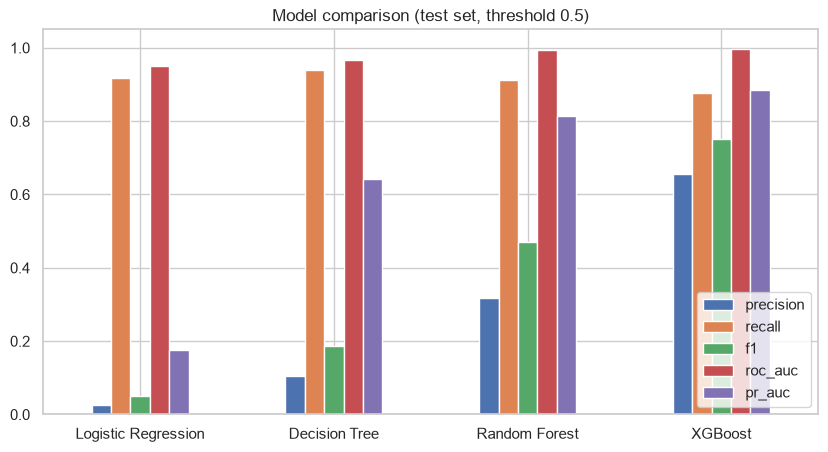

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
scores[["precision", "recall", "f1", "roc_auc", "pr_auc"]].plot.bar(ax=ax, rot=0)
ax.set(ylim=(0, 1.05), title="Model comparison (test set, threshold 0.5)")
ax.legend(loc="lower right")
plt.show()

## 6. Curves and confusion matrices

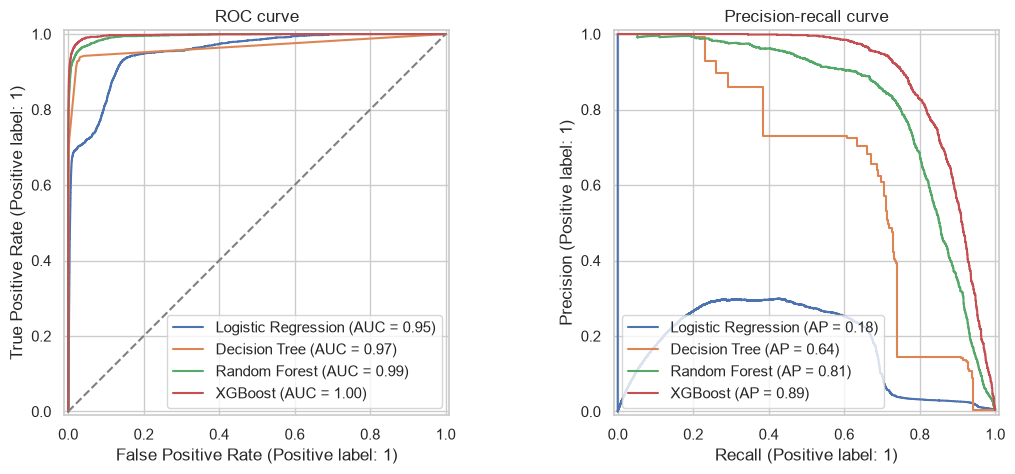

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, pipe in pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(pipe, X_test, y_test, ax=axes[1], name=name)
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set_title("ROC curve")
axes[1].set_title("Precision-recall curve")
plt.show()

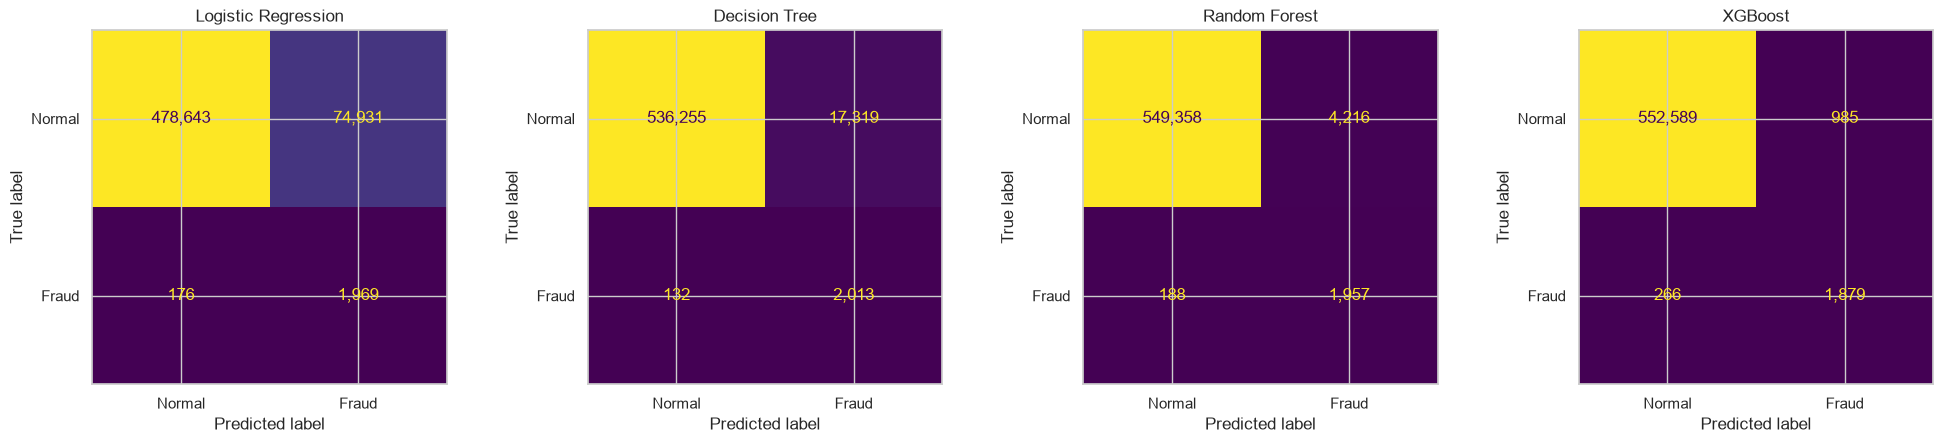

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_test, y_test, display_labels=["Normal", "Fraud"], ax=ax, colorbar=False, values_format=",d",
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 7. Threshold tuning

The default cutoff of 0.5 is not always best. We pick the threshold with the highest F1 on the validation split.

Best model: XGBoost, tuned threshold: 0.923


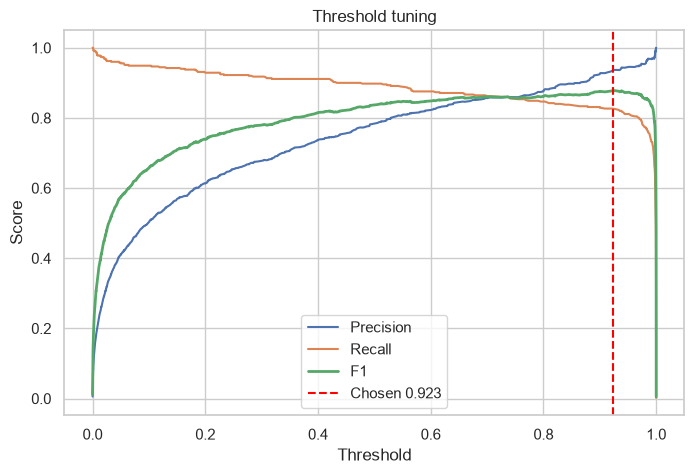

,Default (0.5),Tuned (0.923)
accuracy,0.9977,0.9986
precision,0.6561,0.8481
recall,0.8760,0.7832
f1,0.7502,0.8143
specificity,0.9982,0.9995
roc_auc,0.9972,0.9972
pr_auc,0.8859,0.8859


In [16]:
best_name = scores["pr_auc"].idxmax()
best_pipe = pipelines[best_name]
proba_val = best_pipe.predict_proba(X_val)[:, 1]
threshold = best_threshold(y_val, proba_val)
print(f"Best model: {best_name}, tuned threshold: {threshold:.3f}")

precision, recall, thresholds = precision_recall_curve(y_val, proba_val)
f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, precision[:-1], label="Precision")
ax.plot(thresholds, recall[:-1], label="Recall")
ax.plot(thresholds, f1[:-1], label="F1", lw=2)
ax.axvline(threshold, ls="--", color="red", label=f"Chosen {threshold:.3f}")
ax.set(xlabel="Threshold", ylabel="Score", title="Threshold tuning")
ax.legend()
plt.show()

proba_test = best_pipe.predict_proba(X_test)[:, 1]
pd.DataFrame({
    "Default (0.5)": compute_metrics(y_test, proba_test, 0.5),
    f"Tuned ({threshold:.3f})": compute_metrics(y_test, proba_test, threshold),
}).drop("confusion_matrix")

## 8. Feature importance and decision tree

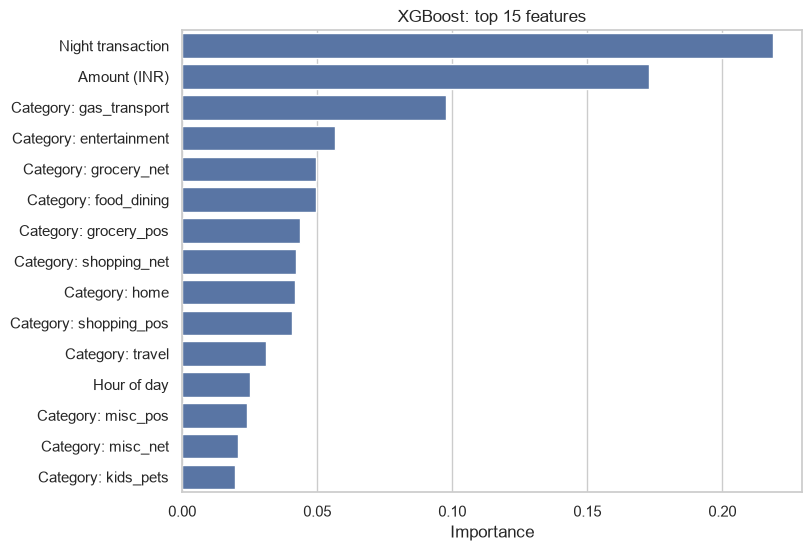

In [17]:
importance = feature_importance(best_pipe).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=importance.values, y=importance.index, ax=ax, color="#4C72B0")
ax.set(title=f"{best_name}: top 15 features", xlabel="Importance", ylabel="")
plt.show()

A shallow decision tree (depth 3) on unscaled features shows how the rules look in plain numbers.

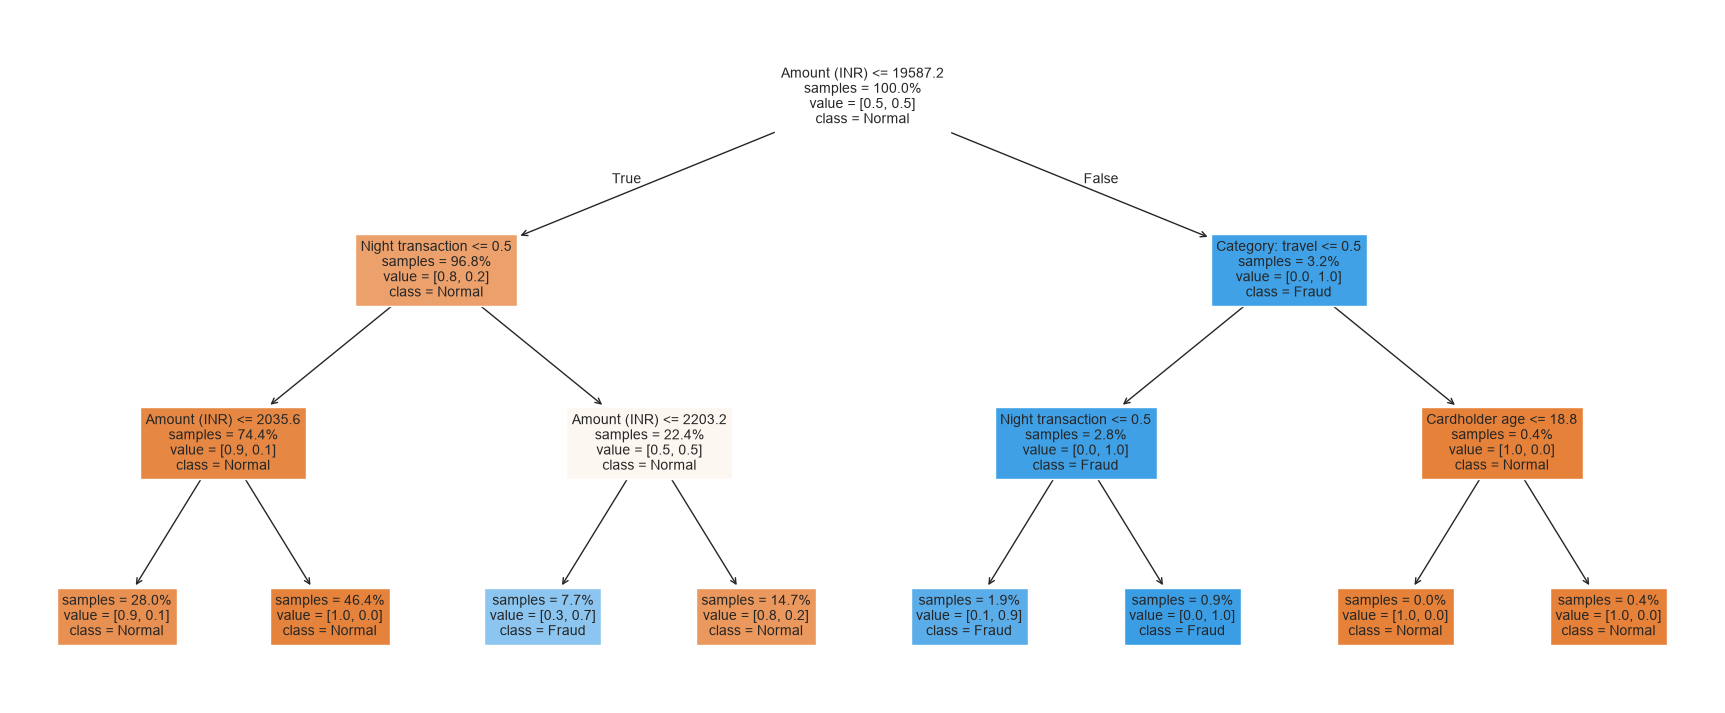

In [18]:
tree_pipe = build_pipeline(
    DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE), scale=False,
).fit(X_fit, y_fit)

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree_pipe.named_steps["model"], feature_names=feature_names(tree_pipe), class_names=["Normal", "Fraud"],
          filled=True, impurity=False, proportion=True, precision=1, fontsize=10, ax=ax)
plt.show()

## 9. Conclusion

- The data is highly imbalanced, so accuracy alone is misleading.
- Amount, night time, spending compared to the card's usual amount and the number of recent transactions are the strongest signals.
- **XGBoost** gives the best PR-AUC and the best balance of precision and recall.
- Tuning the threshold improves the precision and recall trade-off over the default 0.5.
- Run `uv run train.py` to train the final model on all data. Metrics and graphs are saved in `reports/`.